In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from DataTransformation import LowPassFilter
from scipy.signal import argrelextrema
from sklearn.metrics import mean_absolute_error

pd.options.mode.chained_assignment = None


# Plot settings
plt.style.use("fivethirtyeight")
plt.rcParams["figure.figsize"] = (20, 5)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["lines.linewidth"] = 2


In [3]:
#load data

In [4]:
df=pd.read_pickle("../../data/interim/01_data_proccesed.pkl")

In [5]:
df

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set
epoch (ms),,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30
...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048000,-1.041500,-0.076500,1.4146,-5.6218,0.2926,E,row,medium,90
2019-01-20 17:33:27.200,-0.037000,-1.030333,-0.053333,-2.7684,-0.5854,2.2440,E,row,medium,90
2019-01-20 17:33:27.400,-0.060000,-1.031000,-0.082000,2.8416,-5.1342,-0.1220,E,row,medium,90


In [6]:
df = df[df["label"] != "rest"]

acc_r = df["acc_x"] ** 2 + df["acc_y"] ** 2 + df["acc_z"] ** 2
gyr_r = df["gyr_x"] ** 2 + df["gyr_y"] ** 2 + df["gyr_z"] ** 2
df["acc_r"] = np.sqrt(acc_r)
df["gyr_r"] = np.sqrt(gyr_r)

In [7]:
#split data

In [23]:
bench_df = df[df["label"] == "bench"]
squat_df = df[df["label"] == "squat"]
row_df = df[df["label"] == "row"]
ohp_df = df[df["label"] == "ohp"]
dead_df = df[df["label"] == "dead"]

In [24]:
#visulize data to see patterns and repetitions

<AxesSubplot: xlabel='epoch (ms)'>

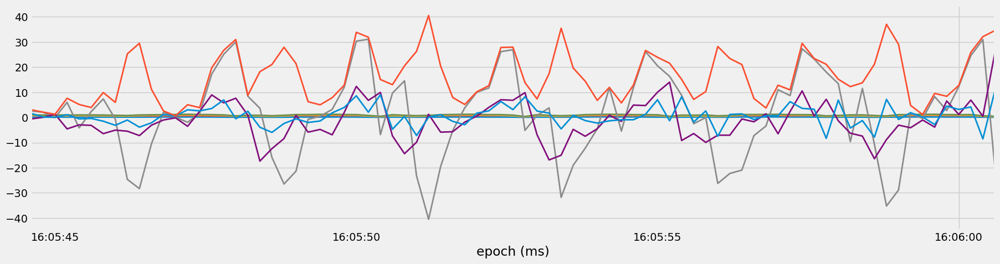

In [25]:
plot_df=squat_df
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_x"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_y"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_z"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_r"].plot()

plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_x"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_y"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_z"].plot()
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_r"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

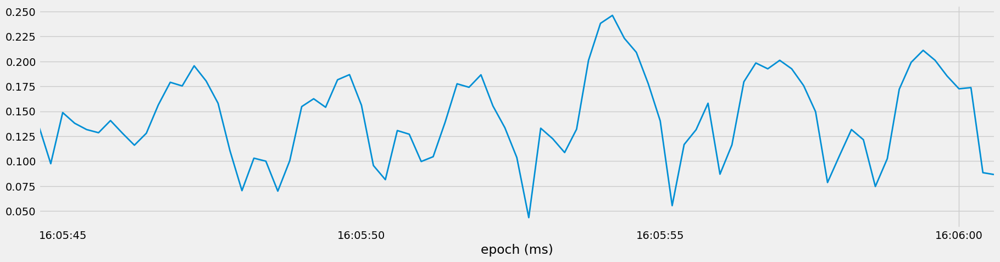

In [26]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_x"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

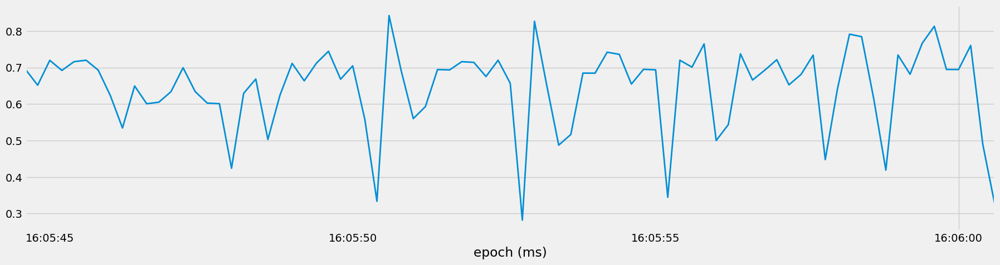

In [27]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_y"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

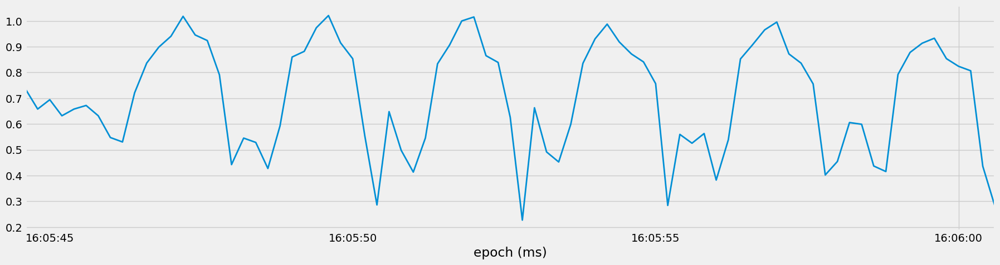

In [28]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_z"].plot()


<AxesSubplot: xlabel='epoch (ms)'>

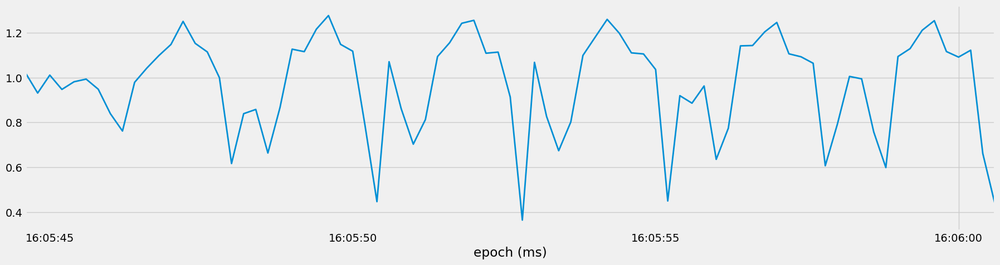

In [29]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["acc_r"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

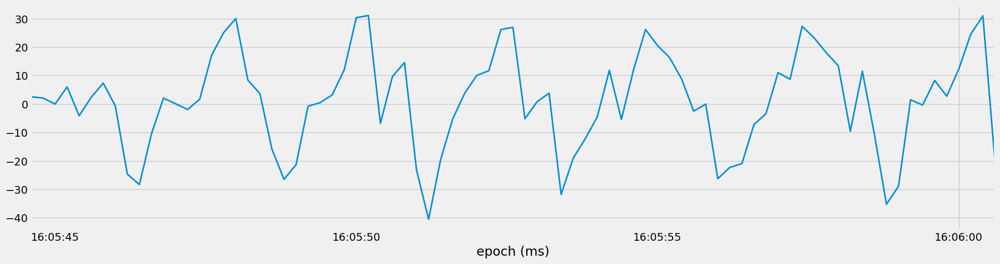

In [30]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_x"].plot()


<AxesSubplot: xlabel='epoch (ms)'>

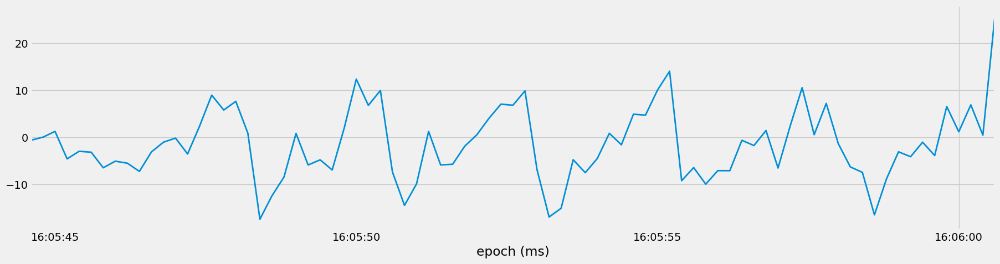

In [31]:

plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_y"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

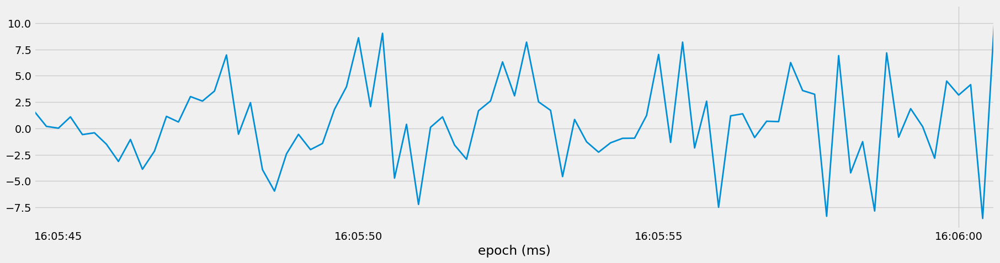

In [32]:

plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_z"].plot()


<AxesSubplot: xlabel='epoch (ms)'>

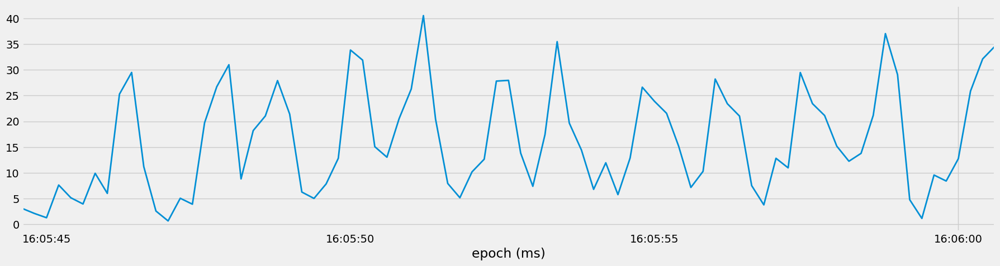

In [33]:
plot_df[plot_df["set"] == plot_df["set"].unique()[0]]["gyr_r"].plot()

In [39]:
fs=1000/200
LowPass=LowPassFilter()


In [40]:
bench_set=bench_df[bench_df["set"] == bench_df["set"].unique()[0]]
squat_set=squat_df[squat_df["set"] == squat_df["set"].unique()[0]]
row_set=row_df[row_df["set"] == row_df["set"].unique()[0]]
ohp_set=ohp_df[ohp_df["set"] == ohp_df["set"].unique()[0]]
dead_set=dead_df[dead_df["set"] == dead_df["set"].unique()[0]]


<AxesSubplot: xlabel='epoch (ms)'>

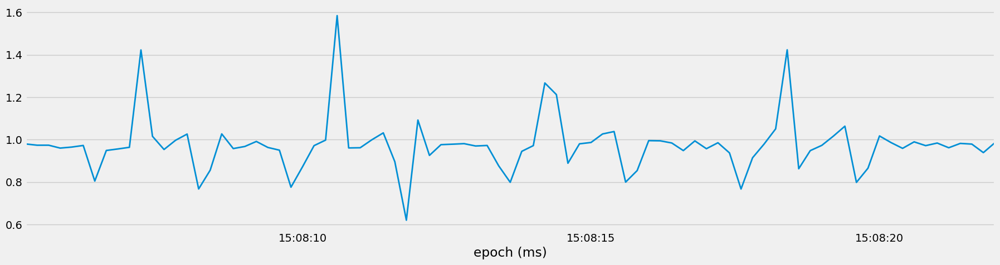

In [41]:
bench_set["acc_r"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

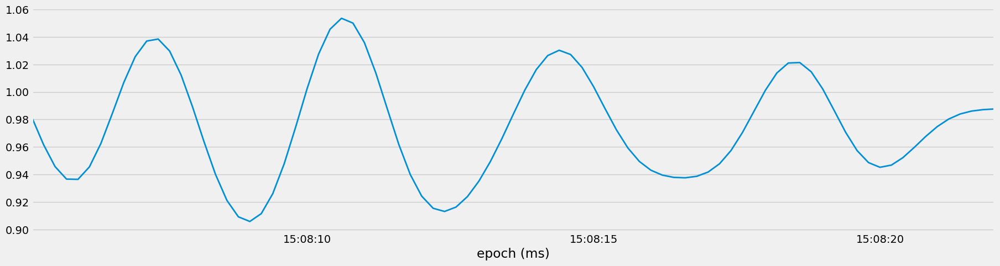

In [53]:
column="acc_r"
LowPass.low_pass_filter(bench_set,col=column, sampling_frequency=fs, cutoff_frequency=0.4, order=5)[column+"_lowpass"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

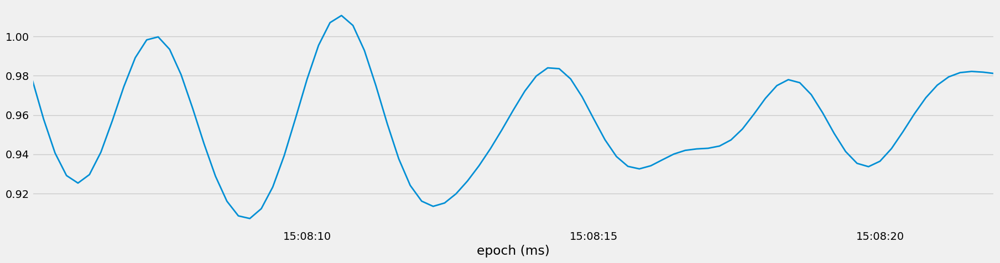

In [54]:
column="acc_y"
LowPass.low_pass_filter(bench_set,col=column, sampling_frequency=fs, cutoff_frequency=0.4, order=5)[column+"_lowpass"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

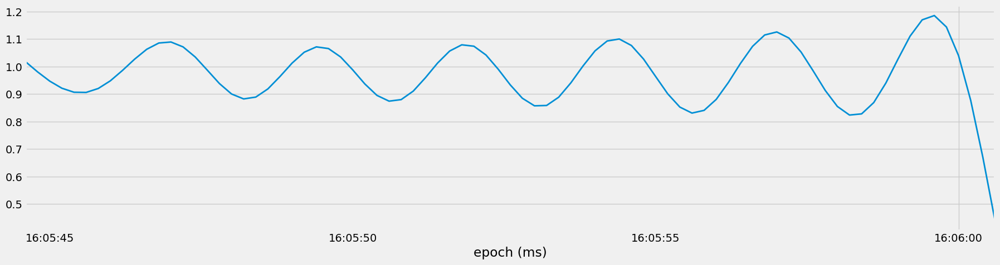

In [55]:
column="acc_r"
LowPass.low_pass_filter(squat_set,col=column, sampling_frequency=fs, cutoff_frequency=0.4, order=5)[column+"_lowpass"].plot()

<AxesSubplot: xlabel='epoch (ms)'>

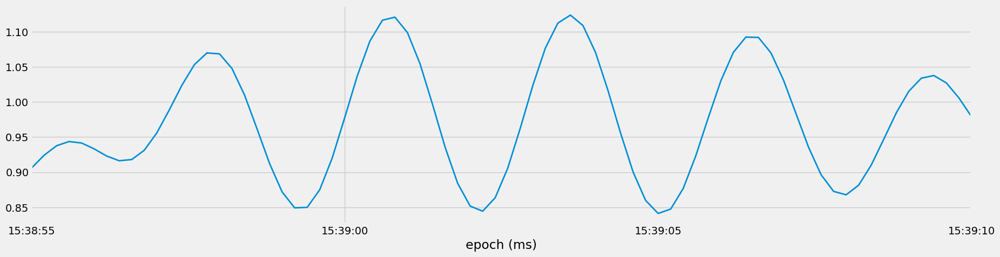

In [57]:
column="acc_r"
LowPass.low_pass_filter(ohp_set,col=column, sampling_frequency=fs, cutoff_frequency=0.4, order=10)[column+"_lowpass"].plot()

In [ ]:
column="acc_y"
data=LowPass.low_pass_filter(ohp_set,col=column, sampling_frequency=fs, cutoff_frequency=0.4, order=10)
argrelextrema(data[column+"_lowpass"].values, np.greater)

array([ 2, 14, 29, 43, 57, 72], dtype=int64)

In [60]:
data

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,acc_r,gyr_r,acc_r_lowpass,acc_y_lowpass
epoch (ms),,,,,,,,,,,,,,
2019-01-11 15:38:55.000,-0.062500,0.901000,0.047000,0.439000,-6.500000,-0.085400,A,ohp,heavy,9,0.904387,6.515368,0.905764,0.902400
2019-01-11 15:38:55.200,-0.080667,1.080667,0.060333,5.597600,-3.219600,-1.426600,A,ohp,heavy,9,1.085351,6.613179,0.923986,0.909372
2019-01-11 15:38:55.400,-0.137500,1.314000,0.024000,20.853400,7.756200,-44.134000,A,ohp,heavy,9,1.321393,49.425023,0.937650,0.912834
2019-01-11 15:38:55.600,-0.234667,0.910333,-0.007000,17.768400,11.488000,-35.000200,A,ohp,heavy,9,0.940119,40.898706,0.943733,0.910690
2019-01-11 15:38:55.800,-0.337000,0.861000,-0.095500,2.377800,2.268200,-4.622000,A,ohp,heavy,9,0.929522,5.671115,0.941585,0.902973
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-11 15:39:09.200,-0.062333,1.201000,-0.006000,-13.475600,0.841400,27.244000,A,ohp,heavy,9,1.202631,30.406172,1.034079,1.025988
2019-01-11 15:39:09.400,0.022500,1.036500,0.028500,3.097400,-2.256000,-3.670600,A,ohp,heavy,9,1.037136,5.306291,1.037802,1.031433
2019-01-11 15:39:09.600,0.000000,0.953667,0.022333,-4.634200,-4.353600,-3.378200,A,ohp,heavy,9,0.953928,7.200130,1.027187,1.021766


In [62]:
indexes = argrelextrema(data[column+"_lowpass"].values, np.greater)
peaks = data.iloc[indexes]
peaks


,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set,acc_r,gyr_r,acc_r_lowpass,acc_y_lowpass
epoch (ms),,,,,,,,,,,,,,
2019-01-11 15:38:55.400,-0.137500,1.314000,0.024000,20.8534,7.7562,-44.1340,A,ohp,heavy,9,1.321393,49.425023,0.937650,0.912834
2019-01-11 15:38:57.800,0.004500,0.895500,0.044500,2.0976,-1.9146,-0.0852,A,ohp,heavy,9,0.896616,2.841281,1.070047,1.055720
2019-01-11 15:39:00.800,-0.094667,0.850000,-0.001333,-6.9636,-2.3412,1.5366,A,ohp,heavy,9,0.855256,7.505603,1.121057,1.099327
2019-01-11 15:39:03.600,-0.065333,0.873333,0.063000,-4.2316,-8.2072,8.9392,A,ohp,heavy,9,0.878037,12.851999,1.124037,1.103036
2019-01-11 15:39:06.400,-0.115333,0.978000,-0.014667,7.0486,-0.5610,-4.9390,A,ohp,heavy,9,0.984886,8.625034,1.092679,1.069436
2019-01-11 15:39:09.400,0.022500,1.036500,0.028500,3.0974,-2.2560,-3.6706,A,ohp,heavy,9,1.037136,5.306291,1.037802,1.031433


In [63]:
#creating a function to count repetitions based on the peaks detected in the low-pass filtered signal.

In [71]:
def count_repetitions(dataset, column="acc_r", sampling_frequency=fs, cutoff_frequency=0.4, order=10):
    data=LowPass.low_pass_filter(dataset,col=column, sampling_frequency=sampling_frequency, cutoff_frequency=cutoff_frequency, order=order)
    indexes = argrelextrema(data[column+"_lowpass"].values, np.greater)
    return len(indexes[0])

In [72]:
count_repetitions(bench_set)

5

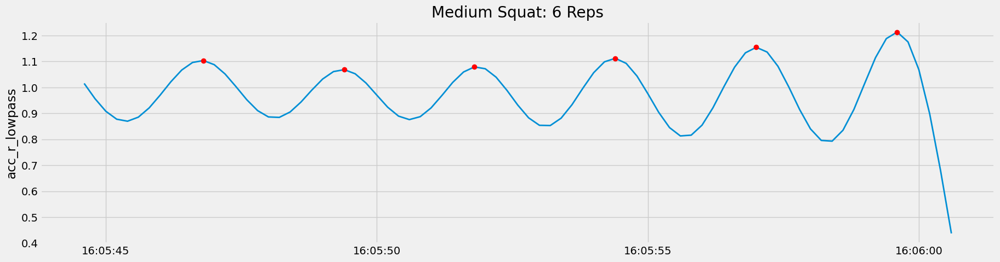

6

In [74]:
def count_reps(dataset, cutoff=0.4, order=10, column="acc_r"):
    data = LowPass.low_pass_filter(
        dataset, col=column, sampling_frequency=fs, cutoff_frequency=cutoff, order=order
    )
    indexes = argrelextrema(data[column + "_lowpass"].values, np.greater)
    peaks = data.iloc[indexes]

    fig, ax = plt.subplots()
    plt.plot(dataset[f"{column}_lowpass"])
    plt.plot(peaks[f"{column}_lowpass"], "o", color="red")
    ax.set_ylabel(f"{column}_lowpass")
    exercise = dataset["label"].iloc[0].title()
    category = dataset["category"].iloc[0].title()
    plt.title(f"{category} {exercise}: {len(peaks)} Reps")
    plt.show()

    return len(peaks)

count_reps(squat_set)

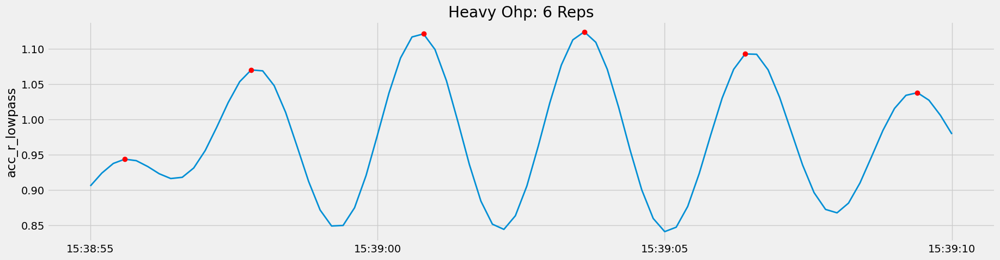

6

In [75]:
def count_reps(dataset, cutoff=0.4, order=10, column="acc_r"):
    data = LowPass.low_pass_filter(
        dataset, col=column, sampling_frequency=fs, cutoff_frequency=cutoff, order=order
    )
    indexes = argrelextrema(data[column + "_lowpass"].values, np.greater)
    peaks = data.iloc[indexes]

    fig, ax = plt.subplots()
    plt.plot(dataset[f"{column}_lowpass"])
    plt.plot(peaks[f"{column}_lowpass"], "o", color="red")
    ax.set_ylabel(f"{column}_lowpass")
    exercise = dataset["label"].iloc[0].title()
    category = dataset["category"].iloc[0].title()
    plt.title(f"{category} {exercise}: {len(peaks)} Reps")
    plt.show()

    return len(peaks)

count_reps(ohp_set)

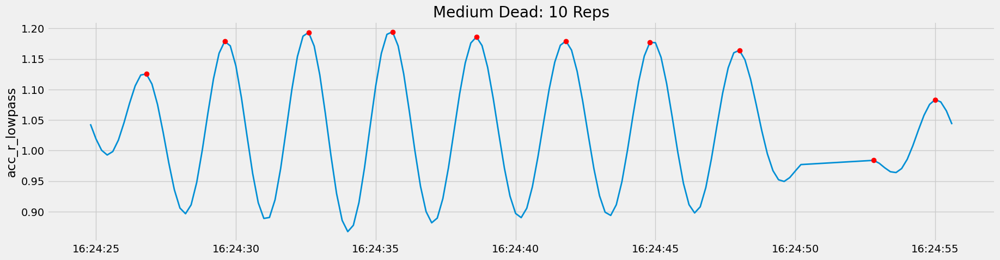

10

In [76]:
def count_reps(dataset, cutoff=0.4, order=10, column="acc_r"):
    data = LowPass.low_pass_filter(
        dataset, col=column, sampling_frequency=fs, cutoff_frequency=cutoff, order=order
    )
    indexes = argrelextrema(data[column + "_lowpass"].values, np.greater)
    peaks = data.iloc[indexes]

    fig, ax = plt.subplots()
    plt.plot(dataset[f"{column}_lowpass"])
    plt.plot(peaks[f"{column}_lowpass"], "o", color="red")
    ax.set_ylabel(f"{column}_lowpass")
    exercise = dataset["label"].iloc[0].title()
    category = dataset["category"].iloc[0].title()
    plt.title(f"{category} {exercise}: {len(peaks)} Reps")
    plt.show()

    return len(peaks)

count_reps(dead_set)

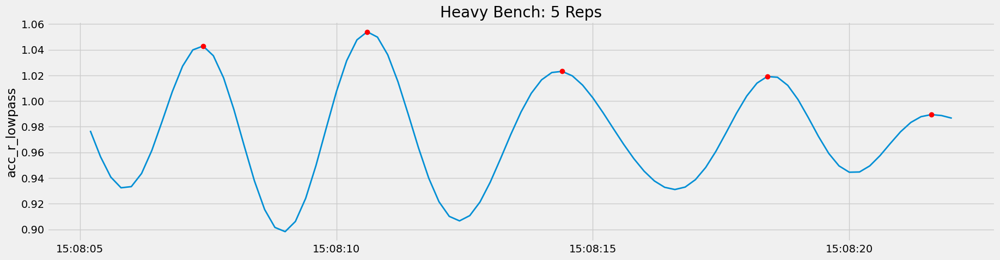

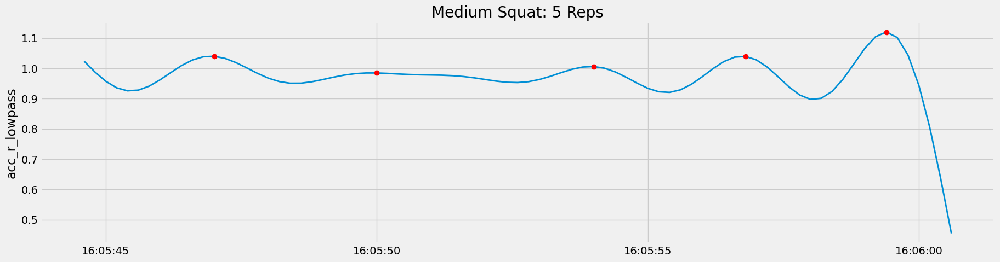

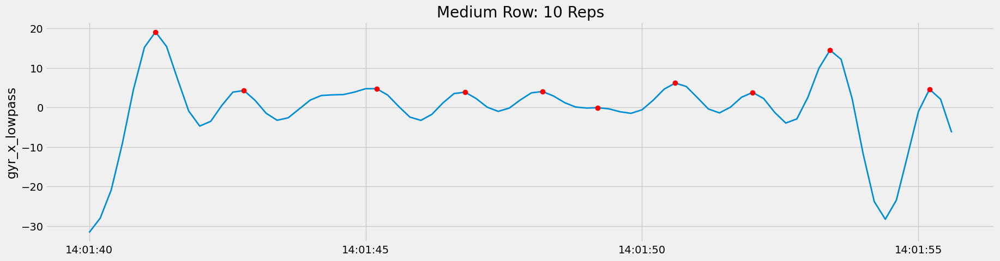

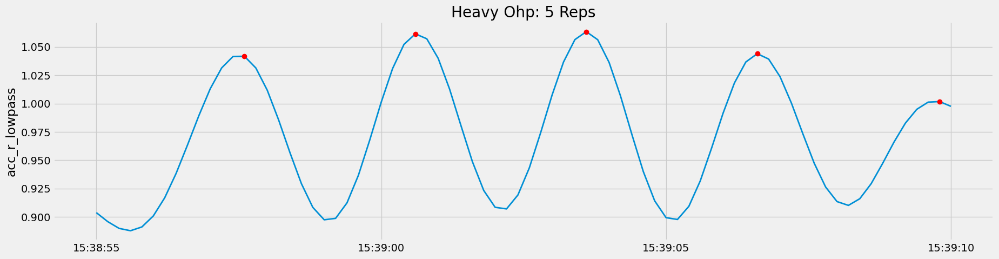

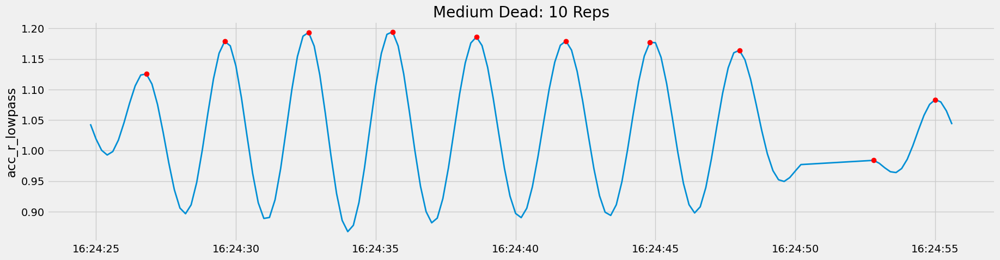

10

In [77]:
count_reps(bench_set, cutoff=0.4)
count_reps(squat_set, cutoff=0.35)
count_reps(row_set, cutoff=0.65, column="gyr_x")
count_reps(ohp_set, cutoff=0.35)
count_reps(dead_set, cutoff=0.4)

In [78]:
# Create benchmark dataframe

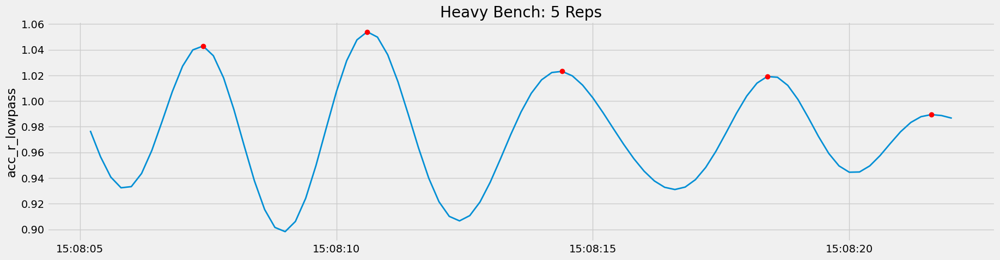

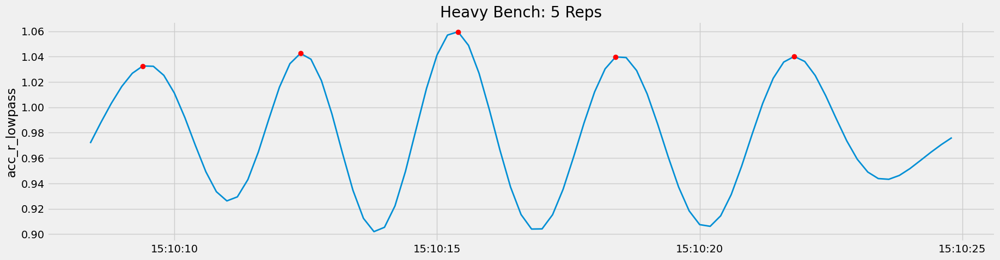

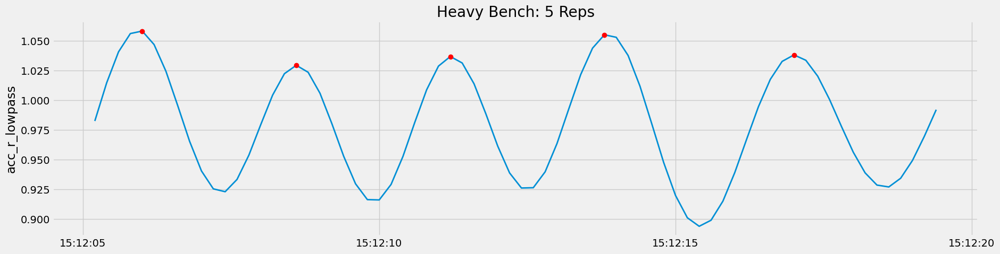

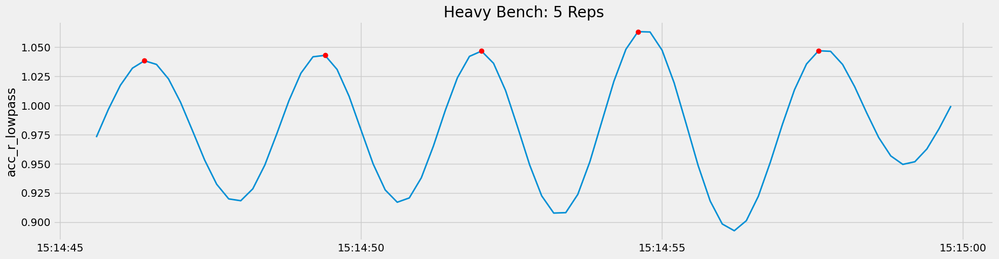

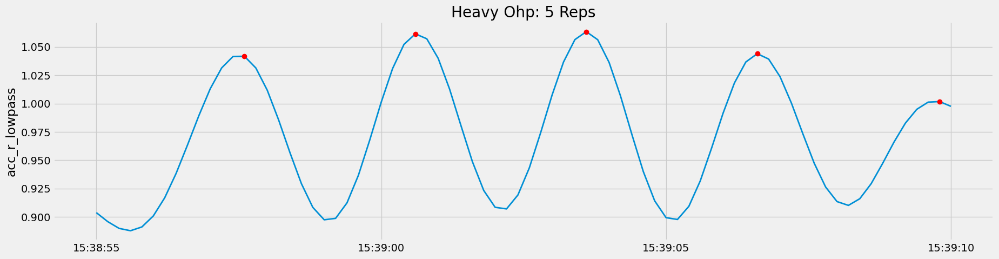

...

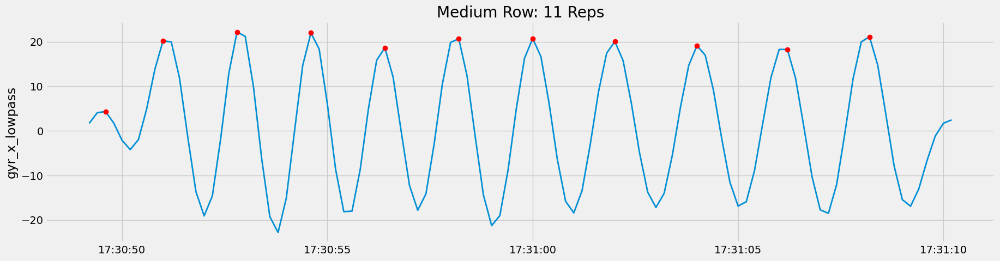

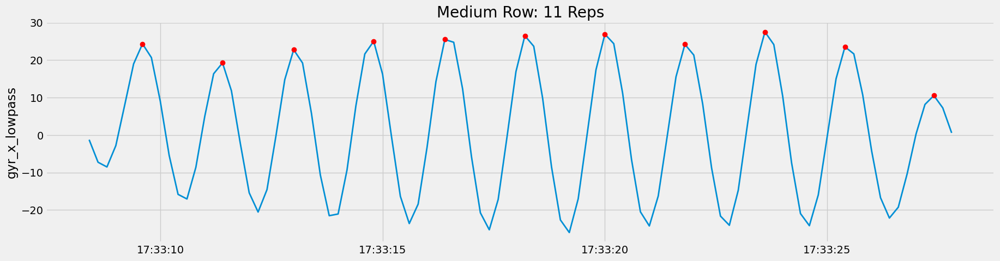

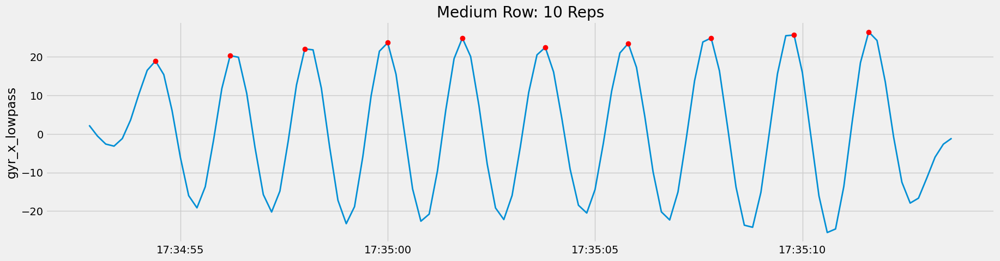

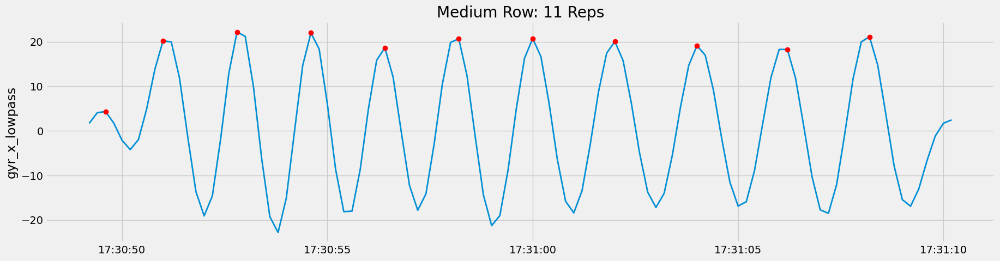

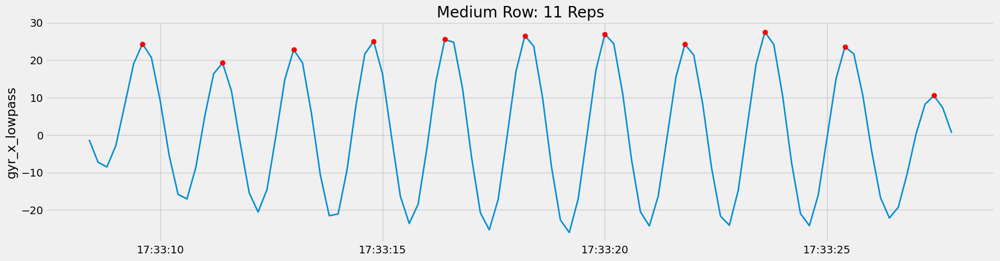

In [81]:
df["reps"] = df["category"].apply(lambda x: 5 if x == "heavy" else 10)
rep_df = df.groupby(["label", "category", "set"])["reps"].max().reset_index()
rep_df["reps_pred"] = 0

for s in df["set"].unique():
    subset=df[df["set"] == s]
    column = "acc_r"
    cutoff = 0.4
    if subset["label"].iloc[0] == "row":
        column = "gyr_x"
        cutoff = 0.65
    if subset["label"].iloc[0] == "squat":
        cutoff = 0.35
    if subset["label"].iloc[0] == "ohp":
        cutoff = 0.35

    reps=count_reps(subset, cutoff=cutoff, column=column)
    rep_df.loc[rep_df["set"] == s, "reps_pred"] = reps

In [82]:
rep_df

,label,category,set,reps,reps_pred
0,bench,heavy,1,5,5
1,bench,heavy,2,5,4
2,bench,heavy,3,5,5
3,bench,heavy,4,5,5
4,bench,heavy,30,5,5
...,...,...,...,...,...
80,squat,medium,28,10,8
81,squat,medium,29,10,8
82,squat,medium,38,10,7
83,squat,medium,63,10,11


In [83]:
error = mean_absolute_error(rep_df["reps"], rep_df["reps_pred"]).round(2)

In [84]:
error

0.88

<AxesSubplot: xlabel='label,category'>

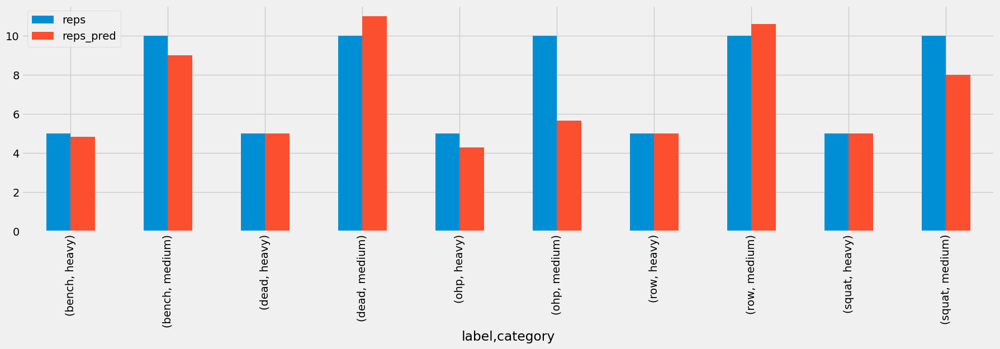

In [90]:
rep_df.groupby(["label", "category"])[["reps", "reps_pred"]].mean().plot.bar()